# k-Nearest Neighbor Klassifikator

Folgendes Diagram zeigt 2D Merkmalvektoren der Klassen "Zahlen" und "Buchstaben" in Form von Zahlen (1-5) und Buchstaben (a-f)


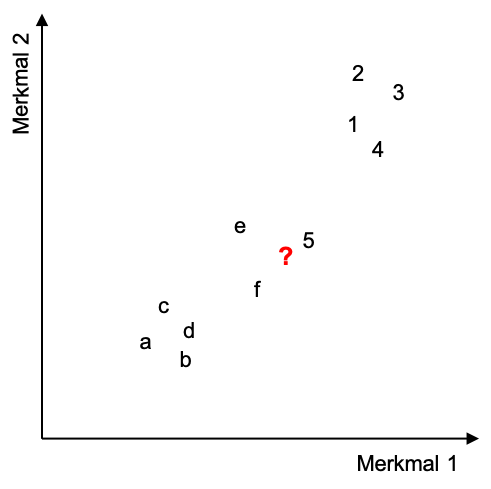

Als Distanzmaß wird der Euklidabstand verwendet.

a) Welche Klasse wird <font color='red'>?</font> bei einem 1-NN Klassifikator zugeweisen?

b) Welche Klasse wird <font color='red'>?</font> bei einem 3-NN Klassifikator zugeweisen?

c) Geben Sie an, wie sich im Falle des 3-NN Klassifikators eine Rückweisung implementieren lässt? Welchen Wert hätte <font color='red'>?</font> in diesem Fall? 

d) Beim kNN Klassifikator müssen die gesamten Trainingsdaten im Speicher gehalten werden. Zur Klassifikation müssen Distanzen für alle Trainingsbeispiele berechnet werden. <br>
  > d1) Wie könnte dieses "Effizienzproblem" gelöst werden? <br>
  > d2) Welche Nachteile hat die Methode aus d1? <br>

a) Klasse Zahlen

b) Klasse Buchstaben

c.I) Fall: 2 Klassen, dann ist eine Rückweisung nicht sinnvoll, denn eine Kombination aus 3 Nachbarn mit 2 Klassen wird immmer eine Mehrheit ergeben.

Daher hätte ? in diesem Fall trotzdem die Klasse Buchstaben.


c.II) Fall: 3 Klassen oder mehr.

Beispiel: Klassen J, K, L

Es müssen mindestens zwei Nachbarn zustimmen, sonst wird der Wert NIL zurückgegeben.

II.1] Nachbarn (K, J, L) => NIL

II.2] Nachbarn (J, L, J) => J

und so weiter


### d (TODO)


# Implementieren des kNN Klassifikators in Python

Implementieren Sie eine Klasse MyKNN, die einen kNN Klassifikator definieren soll. Als Abstandsmaß ist Euklid-Abstand zu implementieren. 

Verwenden Sie die Struktur wie in sklearn:
- Klassifikatoren werden als Klasse repraesentiert
- Es gibt eine fit()- und eine predict()-Methode

## Final Version (see below for older versions and comments on the code)

### Build instructions for haneul.c (dependency):
##### On POSIX systems:
`gcc -D FEATURE_MULTITHREADED -shared -fPIC -fno-strict-aliasing -O2 haneul.c -o libhaneul.so`
##### On Windows:
`cl /D FEATURE_MULTITHREADED /Ox /LD ..\haneul.c /link /EXPORT:fit /EXPORT:predict /EXPORT:init_knn /EXPORT:sort_keys /EXPORT:distance_loop`

In [ ]:
import ctypes
import os

dll_name = "libhaneul.so"
if os.name == "nt": 
    dll_name = "haneul.dll"

haneul = ctypes.CDLL(f"./{dll_name}")

haneul.fit.argtypes = [
    ctypes.POINTER(ctypes.c_double),
    ctypes.POINTER(ctypes.c_int64),
    ctypes.c_size_t, # width
    ctypes.c_size_t,  # height_src
    ctypes.c_size_t,  # max_label
]

haneul.predict.argtypes = [
    ctypes.POINTER(ctypes.c_double),
    ctypes.c_size_t, # width
    ctypes.c_size_t,  # height_new 
    ctypes.c_size_t,  # k_limit
]
haneul.predict.restype = ctypes.POINTER(ctypes.c_int64)

In [ ]:
import numpy as np
from math import sqrt

class MyKNN:
    def __init__(self, target_names, k=1):
        self.label_names = target_names
        self.k = k
        self.width = 0
        self.height_src = 0
        haneul.init_knn()
        
    def fit(self, data: np.ndarray, labels: np.ndarray): 
        assert len(data.shape) == 2
        assert len(labels.shape) == 1
        assert data.shape[0] == labels.shape[0]
        assert data.shape[0] > 0

        data = np.ascontiguousarray(data, dtype=np.float64)
        data_ptr = data.ctypes.data_as(ctypes.POINTER(ctypes.c_double))

        labels_ptr = labels.ctypes.data_as(ctypes.POINTER(ctypes.c_int64))
        
        self.width = (data.shape[1])
        self.height_src = (data.shape[0])
        
        max_label = ctypes.c_size_t(100)
        ret = haneul.fit(data_ptr, labels_ptr, ctypes.c_size_t(self.width), ctypes.c_size_t(self.height_src), max_label)
        assert ret

        
    def predict(self, new_data: np.ndarray):
        assert new_data.flags["C_CONTIGUOUS"]
        assert new_data.shape[0] > 0
        assert new_data.shape[1] == self.width

        new_data_ptr = new_data.ctypes.data_as(ctypes.POINTER(ctypes.c_double));
        width = ctypes.c_size_t(new_data.shape[1])
        height = ctypes.c_size_t(new_data.shape[0])
        k_limit = ctypes.c_size_t(self.k)
        
        results = haneul.predict(new_data_ptr, width, height, k_limit);

        # TODO(yousef): copy data so we do not *accidently* write to memory owned by another process
        array = np.ctypeslib.as_array(results, shape=(new_data.shape[0],))
        return array

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

X, y = make_blobs(
    n_samples=10_000,
    n_features=2,
    centers=3,
    cluster_std=1.5,
    random_state=42
)

x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1

xx1, xx2 = np.meshgrid(
    np.arange(x1_min, x1_max, 0.1),
    np.arange(x2_min, x2_max, 0.1)
)

grid_points = np.c_[xx1.ravel(), xx2.ravel()]

print(grid_points.shape)

In [ ]:
chosen_k = 11

yousef_knn = MyKNN(None, k=chosen_k)
yousef_knn.fit(X, y)

In [ ]:
%time Z = yousef_knn.predict(grid_points)

Z = Z.reshape(xx1.shape)

plt.contourf(xx1, xx2, Z, alpha=0.3)
plt.scatter(X[:, 0], X[:, 1], c=y, s=10, edgecolor='k')

plt.title("Yousef's KNN")
plt.show()

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
ref_knn = KNeighborsClassifier(n_neighbors=chosen_k)

ref_knn.fit(X,y)

In [ ]:
%time Z = ref_knn.predict(grid_points) 

Z = Z.reshape(xx1.shape)

plt.contourf(xx1, xx2, Z, alpha=0.3)
plt.scatter(X[:, 0], X[:, 1], c=y, s=10, edgecolor='k')

plt.title("Reference KNN")
plt.show()

## Version 0: Mostly Python. Only sort_keys delegated to a foreign c function.

In [ ]:
import numpy as np
from math import sqrt

def dist(ref, inp):
    assert len(ref) == len(inp)
    agg = 0
    for i in range(0, len(ref)):
        agg += (ref[i] - inp[i]) ** 2

    return sqrt(agg)

class MyKNN:
    def __init__(self, target_names, k=1):
        self.label_names = target_names
        self.k = k
        self.data = None
        self.labels = None
        self.keys = None
        self.transient_results = None
        self.indices = None
        
    def fit(self, data: np.ndarray, labels: np.ndarray): 
        assert len(data.shape) == 2
        assert len(labels.shape) == 1
        assert data.shape[0] == labels.shape[0]
        assert data.shape[0] > 0
        
        self.data = np.ascontiguousarray(data, dtype=np.float64)
        self.labels = labels
        self.transient_results = np.zeros(self.data.shape[0], dtype=np.int64)
        self.indices = np.zeros(len(self.data), dtype=np.uint64)
        self.keys = np.zeros(self.data.shape[0], dtype=np.float32)
        
    def predict(self, new_data: np.ndarray):
        assert new_data.shape[0] > 0
        assert new_data.shape[1] == self.data.shape[1]

        if len(new_data) > len(self.transient_results):
            self.transient_results = np.resize(self.transient_results, (len(new_data),))
        
        for res_at, vec in enumerate(new_data):
            for i in range(len(self.data)):
                self.keys[i] = dist(self.data[i], vec)

            # reinterpret floats as u32 (without copying)
            keys_u32 = self.keys.view(np.uint32)
            
            keys_ptr = keys_u32.ctypes.data_as(ctypes.POINTER(ctypes.c_uint32))
            indices_ptr = self.indices.ctypes.data_as(ctypes.POINTER(ctypes.c_uint64))
            len_keys = len(keys_u32) 
            
            haneul.sort_keys(keys_ptr, len_keys, indices_ptr);
            
            k_labels = [self.labels[i] for i in self.indices[:self.k+1]]
            
            counts = np.bincount(k_labels)
            max_label = np.argmax(counts)
            
            self.transient_results[res_at] = max_label

        return self.transient_results

### SCALE DOWN THE TEST BECAUSE VERSION 0 IS VERY SLOW

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

X_small, y_small = make_blobs(
    n_samples=1000,
    n_features=2,
    centers=3,
    cluster_std=1.5,
    random_state=42
)

x1_min_s, x1_max_s = X_small[:, 0].min() - 1, X_small[:, 0].max() + 1
x2_min_s, x2_max_s = X_small[:, 1].min() - 1, X_small[:, 1].max() + 1

xx1_small, xx2_small = np.meshgrid(
    np.arange(x1_min_s, x1_max_s, 0.1),
    np.arange(x2_min_s, x2_max_s, 0.1)
)

grid_points_small = np.c_[xx1_small.ravel(), xx2_small.ravel()]

print(grid_points_small.shape)

In [ ]:
chosen_k = 11

version0 = MyKNN(None, k=chosen_k)
version0.fit(X_small, y_small)

In [ ]:
%time Z = version0.predict(grid_points_small)

Z = Z.reshape(xx1_small.shape)

plt.contourf(xx1_small, xx2_small, Z, alpha=0.3)
plt.scatter(X_small[:, 0], X_small[:, 1], c=y_small, s=10, edgecolor='k')

plt.title("Version 0 KNN")
plt.show()

### COMMENTS ON VERSION 0
I. Intentions

(1) Why sort? Why do the sort in C?

Clearly we need a way to get the labels of the k data points which are closest to the input vector.

A quick search yielded "numpy.argsort()" which does what I want.

It returns the indices that would sort distances[]. These indices we can use to get the corresponding labels.

The problem is that argsort() creates a new array which made me reject the solution. Allocating new arrays inside a loop was not something I was interested in doing, and I knew from the shape of the problem that I would be fine with sorting in place. C gave me the control needed to do that.

II. Examining the Results

(1) Correctness: Visualising the results, I knew I was in the right direction, so I didn't worry much.

(2) Speed: When I increased the amount of inputted data, it became painfully clear that my solution was slow. Improving the runtime became the goal for the next iterations.

## Version 1: Logic still in Python. Delegating distance calculation.

In [ ]:
import numpy as np
from math import sqrt

# PYTHON dist() ROUTINE REMOVED

class MyKNN:
    def __init__(self, target_names, k=1):
        self.label_names = target_names
        self.k = k
        self.data = None
        self.labels = None
        self.keys = None
        self.transient_results = None
        self.indices = None
        
    def fit(self, data: np.ndarray, labels: np.ndarray): 
        assert len(data.shape) == 2
        assert len(labels.shape) == 1
        assert data.shape[0] == labels.shape[0]
        assert data.shape[0] > 0
        
        self.data = np.ascontiguousarray(data, dtype=np.float64)
        self.labels = labels
        self.transient_results = np.zeros(self.data.shape[0], dtype=np.int64)
        self.indices = np.zeros(len(self.data), dtype=np.uint64)
        self.keys = np.zeros(self.data.shape[0], dtype=np.float32)
        
    def predict(self, new_data: np.ndarray):
        assert new_data.shape[0] > 0
        assert new_data.shape[1] == self.data.shape[1]

        if len(new_data) > len(self.transient_results):
            self.transient_results = np.resize(self.transient_results, (len(new_data),))
        
        for res_at, vec in enumerate(new_data):
            dist_ptr = self.keys.ctypes.data_as(ctypes.POINTER(ctypes.c_float))
            data_ptr = self.data.ctypes.data_as(ctypes.POINTER(ctypes.c_double))
            vec_ptr = vec.ctypes.data_as(ctypes.POINTER(ctypes.c_double)) 

            # NEW ADDITION
            haneul.distance_loop(dist_ptr, data_ptr, vec_ptr, len(vec), len(self.data)) 

            # reinterpret floats as u32 (without copying)
            keys_u32 = self.keys.view(np.uint32)

            keys_ptr = keys_u32.ctypes.data_as(ctypes.POINTER(ctypes.c_uint32))    
            indices_ptr = self.indices.ctypes.data_as(ctypes.POINTER(ctypes.c_uint64))
            len_keys = len(keys_u32) 
            
            haneul.sort_keys(keys_ptr, len_keys, indices_ptr);
            
            k_labels = [self.labels[i] for i in self.indices[:self.k+1]]
            
            counts = np.bincount(k_labels)
            max_label = np.argmax(counts)
            
            self.transient_results[res_at] = max_label

        return self.transient_results

In [ ]:
chosen_k = 11

version1 = MyKNN(None, k=chosen_k)
version1.fit(X, y)

In [ ]:
%time Z = version1.predict(grid_points)

Z = Z.reshape(xx1.shape)

plt.contourf(xx1, xx2, Z, alpha=0.3)
plt.scatter(X[:, 0], X[:, 1], c=y, s=10, edgecolor='k')

plt.title("Version 1 (w/ Original Dataset)")
plt.show()

## COMMENTS ON VERSION 1
I. Intentions

Again, going just by instincts, loops and intensive maths are not suitable for interpreted Python. The major step for this version was rewriting the distance calculation in C.

II. Examining the Results

Runtime: this version crushed the scaled down dataset (many times faster than v0) but still struggled with the original one, requiring ca. 20s for it on my machine. The goal for the next version was to do some profiling and see where the program spent most of its time.

## COMMENTS ON VERSIONS 2 and 3 (source code forgone)
I. Intentions (& Steps Taken)

I had a hard time gathering runtime information in Jupyter, so I turned to Visual Studio's debugger. I began by porting the predict() routine to C so I can profile it with MSVC.

After some time, it became clear that **sorting** the array of distances **dominated** the runtime.

Knowing that, I worked on the one thing that had been on my mind from the start. I had known that a full sort was not needed but had postponed replacing it with a selection algorithm.
I implemented Quickselect by translating the pseudocode from [Wikipedia](https://en.wikipedia.org/wiki/Quickselect) and using the same partitioning routine I had already used for qsort.

II. Examining the Results 

(1) Though significantly more palatable, the predict routine (now using Quickselect) was still slower than the reference classifier provided by sklearn. The next step was to make it multithreaded.

(2) An ongoing theme in this document is that my implementation does more work than necessary. Sorting instead of selecting is one example. Another example is that excess data, irrelevant to label-assignment, is never pruned or ignored. I am brute-forcing all possible calculations. Keywords in this context are 'Ball tree', 'k-d tree', et cetera. I never followed through in this direction.

## COMMENTS ON FINAL VERSION

## Bestimmen Sie die Güte Ihres Klassifikators und Testen Sie unterschiedliche Werte für k.

## Zerlegen Sie die Daten in ein Trainings- und Testset und testen Sie erneut.

## Verwenden Sie ein Validierungsset zur Bestimmung eines geeigneten Parameters k

## Verwenden Sie eine Kreuzvalidierung zur Bestimmung von k

